In [1]:

import pandas as pd

# Define all 26 columns
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Read the training dataset
df = pd.read_csv(
    "data/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
print(df.head())

# Inspect number of engines
print("Number of engines:", df["engine_id"].nunique())

# Inspect the first engine
engine_1 = df[df["engine_id"] == 1]

print("Engine 1 cycles:", len(engine_1))
print(engine_1[["engine_id", "cycle", "sensor_2",
                "sensor_3"]].head())


Dataset shape: (20631, 26)
   engine_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_2

In [2]:

# Find each engine's final cycle
df["max_cycle"] = df.groupby("engine_id")["cycle"].transform("max")

# Calculate RUL
df["RUL"] = df["max_cycle"] - df["cycle"]

# Remove temporary column
df = df.drop(columns=["max_cycle"])

# Inspect Engine 1
print(
    df[df["engine_id"] == 1][
        ["engine_id", "cycle", "sensor_2", "RUL"]
    ].tail(10)
)


     engine_id  cycle  sensor_2  RUL
182          1    183    643.24    9
183          1    184    644.07    8
184          1    185    643.80    7
185          1    186    643.51    6
186          1    187    643.32    5
187          1    188    643.75    4
188          1    189    644.18    3
189          1    190    643.64    2
190          1    191    643.34    1
191          1    192    643.54    0


Dataset shape: (20631, 26)
Total engines: 100


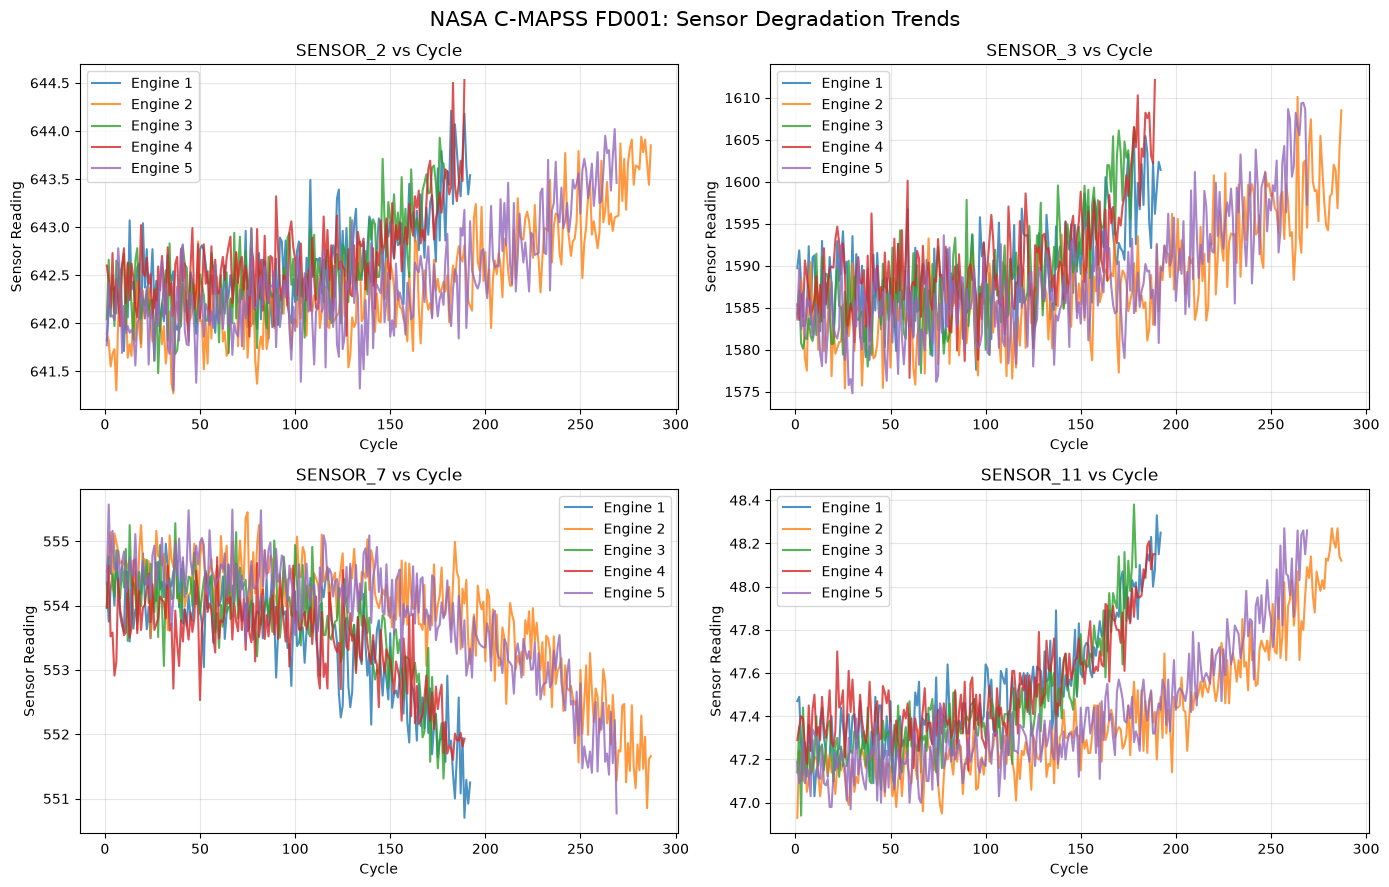


Constant sensors across FD001:
sensor_1
sensor_5
sensor_10
sensor_16
sensor_18
sensor_19

Sensor trend analysis:

sensor_2
Engine 1: initial=642.325, final=643.255, change=+0.930
Engine 2: initial=641.985, final=643.242, change=+1.258
Engine 3: initial=642.273, final=643.225, change=+0.951
Engine 4: initial=642.415, final=643.269, change=+0.855
Engine 5: initial=642.076, final=643.234, change=+1.159

sensor_3
Engine 1: initial=1587.174, final=1596.367, change=+9.193
Engine 2: initial=1583.324, final=1597.566, change=+14.242
Engine 3: initial=1584.621, final=1597.843, change=+13.222
Engine 4: initial=1587.458, final=1598.633, change=+11.175
Engine 5: initial=1583.395, final=1598.287, change=+14.892

sensor_7
Engine 1: initial=554.193, final=552.060, change=-2.133
Engine 2: initial=554.525, final=552.338, change=-2.187
Engine 3: initial=554.297, final=552.786, change=-1.510
Engine 4: initial=553.891, final=552.426, change=-1.464
Engine 5: initial=554.596, final=552.506, change=-2.090

s

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the FD001 training dataset
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

df = pd.read_csv(
    "data/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
print("Total engines:", df["engine_id"].nunique())

# 2. Select engines and sensors
engine_ids = [1, 2, 3, 4, 5]
sensors = ["sensor_2", "sensor_3", "sensor_7", "sensor_11"]

selected_df = df[df["engine_id"].isin(engine_ids)]

# 3. Plot each sensor separately
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, sensor in zip(axes.flat, sensors):

    for engine_id in engine_ids:
        engine_data = selected_df[selected_df["engine_id"] == engine_id]

        ax.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=f"Engine {engine_id}",
            linewidth=1.5,
            alpha=0.8
        )

    ax.set_title(f"{sensor.upper()} vs Cycle")
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Sensor Reading")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("NASA C-MAPSS FD001: Sensor Degradation Trends",fontsize=15)

plt.tight_layout()
plt.savefig("fd001_sensor_trends.png", dpi=300)
plt.show()

# 4. Find completely constant sensors
all_sensors = [f"sensor_{i}" for i in range(1, 22)]

print("\nConstant sensors across FD001:")

for sensor in all_sensors:
    if df[sensor].nunique() == 1:
        print(sensor)

# 5. Calculate trend direction for each selected engine
print("\nSensor trend analysis:")

for sensor in sensors:
    print(f"\n{sensor}")

    for engine_id in engine_ids:
        engine_data = selected_df[
            selected_df["engine_id"] == engine_id
        ].sort_values("cycle")

        # Compare the first and last 20% of cycles
        n = max(1, len(engine_data) // 5)

        initial = engine_data[sensor].iloc[:n].mean()
        final = engine_data[sensor].iloc[-n:].mean()

        difference = final - initial

        print(
            f"Engine {engine_id}: "
            f"initial={initial:.3f}, "
            f"final={final:.3f}, "
            f"change={difference:+.3f}"
        )
